<a href="https://colab.research.google.com/github/matheusgustavo23/ciencia-de-dados-unijui/blob/main/analise_vendas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

dados = {
    "Mes": ["Jan", "Fev", "Mar", "Abr", "Mai", "Jun"],
    "Notebook": [20, 25, 22, 30, 35, 40],
    "Mouse": [50, 55, 48, 60, 65, 70],
    "Teclado": [30, 28, 35, 40, 38, 45]
}

df = pd.DataFrame(dados)
print(df)

   Mes  Notebook  Mouse  Teclado
0  Jan        20     50       30
1  Fev        25     55       28
2  Mar        22     48       35
3  Abr        30     60       40
4  Mai        35     65       38
5  Jun        40     70       45


In [2]:
print("Primeiras linhas:")
print(df.head())

Primeiras linhas:
   Mes  Notebook  Mouse  Teclado
0  Jan        20     50       30
1  Fev        25     55       28
2  Mar        22     48       35
3  Abr        30     60       40
4  Mai        35     65       38


In [3]:
print("Dimensões:", df.shape)
print("Linhas (meses):", df.shape[0])
print("Colunas:", df.shape[1])

Dimensões: (6, 4)
Linhas (meses): 6
Colunas: 4


In [ ]:
df.describe()

,Notebook,Mouse,Teclado
count,6.000000,6.000000,6.000000
mean,28.666667,58.000000,36.000000
std,7.788881,8.602325,6.356099
min,20.000000,48.000000,28.000000
25%,22.750000,51.250000,31.250000
50%,27.500000,57.500000,36.500000
75%,33.750000,63.750000,39.500000
max,40.000000,70.000000,45.000000


In [ ]:
produtos = ["Notebook", "Mouse", "Teclado"]

for produto in produtos:
    vendas = np.array(df[produto])   # transformo a coluna em array do NumPy

    media = np.mean(vendas)
    maior = np.max(vendas)
    menor = np.min(vendas)

    print(produto)
    print("  Média:", round(media, 2))
    print("  Maior venda:", maior)
    print("  Menor venda:", menor)

Notebook
  Média: 28.67
  Maior venda: 40
  Menor venda: 20
Mouse
  Média: 58.0
  Maior venda: 70
  Menor venda: 48
Teclado
  Média: 36.0
  Maior venda: 45
  Menor venda: 28


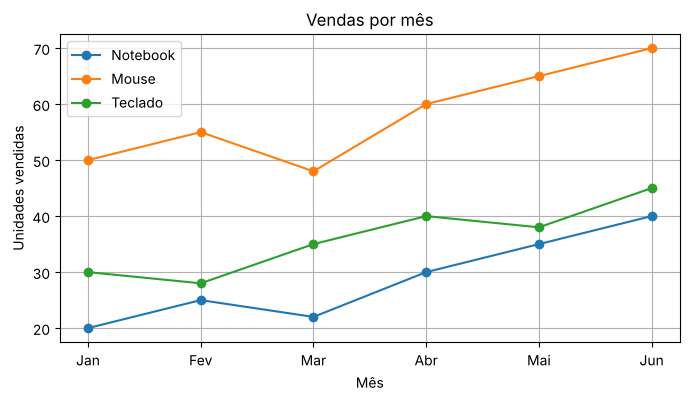

In [ ]:
plt.figure(figsize=(8, 4))

for produto in produtos:
    plt.plot(df["Mes"], df[produto], marker="o", label=produto)

plt.title("Vendas por mês")
plt.xlabel("Mês")
plt.ylabel("Unidades vendidas")
plt.legend()
plt.grid(True)
plt.show()

Totais: [172, 348, 216]


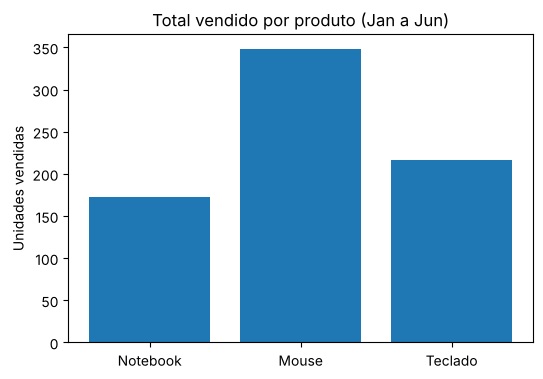

In [ ]:
totais = []
for produto in produtos:
    totais.append(int(np.sum(df[produto])))

print("Totais:", totais)

plt.figure(figsize=(6, 4))
plt.bar(produtos, totais)
plt.title("Total vendido por produto (Jan a Jun)")
plt.ylabel("Unidades vendidas")
plt.show()

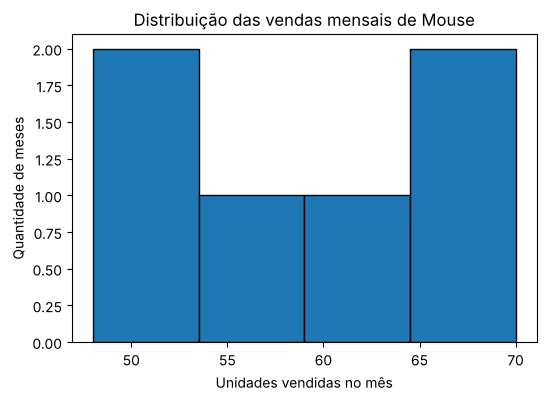

In [ ]:
plt.figure(figsize=(6, 4))
plt.hist(df["Mouse"], bins=4, edgecolor="black")
plt.title("Distribuição das vendas mensais de Mouse")
plt.xlabel("Unidades vendidas no mês")
plt.ylabel("Quantidade de meses")
plt.show()

In [ ]:
# produto com maior volume total
posicao = np.argmax(totais)   # argmax devolve a posição do maior valor
print("Produto com maior volume total:", produtos[posicao], "com", totais[posicao], "unidades")
print()

# mês de maior venda de cada produto
for produto in produtos:
    linha = df[produto].idxmax()     # índice da linha com o maior valor
    mes = df["Mes"][linha]
    print("Maior venda de", produto, "foi em", mes, "com", df[produto][linha], "unidades")

Produto com maior volume total: Mouse com 348 unidades

Maior venda de Notebook foi em Jun com 40 unidades
Maior venda de Mouse foi em Jun com 70 unidades
Maior venda de Teclado foi em Jun com 45 unidades


In [ ]:
teclado = np.array(df["Teclado"])
meses = list(df["Mes"])

variacoes = []
meses_variacao = []

# começo no 1 porque janeiro não tem mês anterior para comparar
for i in range(1, len(teclado)):
    variacao = (teclado[i] - teclado[i - 1]) / teclado[i - 1] * 100
    variacoes.append(round(variacao, 1))
    meses_variacao.append(meses[i])

for i in range(len(variacoes)):
    print(meses_variacao[i], ":", variacoes[i], "%")

Fev : -6.7 %
Mar : 25.0 %
Abr : 14.3 %
Mai : -5.0 %
Jun : 18.4 %


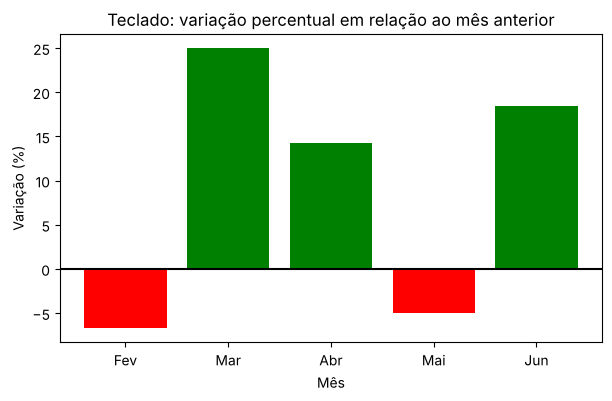

In [ ]:
# verde quando cresceu, vermelho quando caiu
cores = []
for v in variacoes:
    if v >= 0:
        cores.append("green")
    else:
        cores.append("red")

plt.figure(figsize=(7, 4))
plt.bar(meses_variacao, variacoes, color=cores)
plt.axhline(0, color="black")   # linha do zero, separa crescimento de queda
plt.title("Teclado: variação percentual em relação ao mês anterior")
plt.xlabel("Mês")
plt.ylabel("Variação (%)")
plt.show()